In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pistack_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(pistack_dir)
df = pd.read_csv('salt_bridge_EDA.csv', index_col=0)
# df = raw_df.query('TOTAL < 0')
df.shape

(1976, 39)

In [92]:
print(len(df.query('TOTAL > 0'))) 
print(len(df.query('TOTAL < 0')))
df.query('TOTAL > 0')

5
1971


,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,...,PAULI,DISP,CLS_ELEC,MOD_PAULI,CLS_DISP,PREPARATION,FROZEN,POLARIZATION,CHARGE_TRANSFER,TOTAL
6ar9_3L4_D_301_338_ASP_9_5394-5395,6ar9,6ar9_3L4_D_301,pdbbind_opt_sm/,338,ASP,D,5394 5395,1,UNL,Z,...,1.6940,-2.7297,369.5013,0.3186,NaN,0.0,367.0902,-12.0842,-0.2048,354.8012
3h26_B56_A_901_184_ASP_3-6_2872-2873,3h26,3h26_B56_A_901,pdbbind_opt_sm/,184,ASP,A,2872 2873,1,UNL,Z,...,259.6140,-29.5380,7.4041,164.0010,NaN,-0.0,141.8672,-65.9623,-31.0512,44.8536
6fh3_RPI_B_401_634_ASP_7-10_10044-10045,6fh3,6fh3_RPI_B_401,pdbbind_opt_sm/,634,ASP,B,10044 10045,1,UNL,Z,...,42.6691,-16.9106,219.0166,20.1900,NaN,0.0,222.2960,-15.4436,-2.2069,204.6456
5hbn_RPI_A_206_29_GLU_7-10_471-472,5hbn,5hbn_RPI_A_206,pdbbind_opt_sm/,29,GLU,A,471 472,1,UNL,Z,...,223.7273,-29.0280,82.5471,133.3325,NaN,-0.0,186.8516,-59.8873,-31.7068,95.2575
3n2c_LWY_N_427_321_ASP_2_4757-4758,3n2c,3n2c_LWY_N_427,pdbbind_opt_sm/,321,ASP,N,4757 4758,1,UNL,Z,...,119.5726,-28.8037,341.4958,49.1539,NaN,0.0,361.8460,-37.0967,-2.5977,322.1515


# Charge Number Classification

In [90]:
charge0 = set()
charge1 = set()

restype = set()
lig_group = set()

for index, row in df.iterrows():
    charge0.add(row['charge0'])
    charge1.add(row['charge1'])
    restype.add(row['restype'])
    lig_group.add(row['lig_group'])


print(f'charge ligand: {charge0}')
print(f'charge protein: {charge1}')
print(f'restypes: {restype}')
print(f'lig_groups: {lig_group}\n')

restype_lig_group = {
    'HIS': set(), 
    'ARG': set(), 
    'ASP': set(), 
    'LYS': set(),
    'GLU': set()
}

for index, row in df.iterrows():
    restype_lig_group[row['restype']].add(row['lig_group'])

print(f'restype_ligand interaction pairs: {restype_lig_group}\n')

charge ligand: {1.0, 2.0, -2.0, -5.0, -4.0, -3.0, -1.0}
charge protein: {1.0, -1.0}
restypes: {'HIS', 'ARG', 'ASP', 'LYS', 'GLU'}
lig_groups: {'Sulfonicacid', 'Carboxylate', 'Phosphate', 'Sulfate', 'Tertamine', 'Guanidine', 'Quartamine', 'Sulfonium'}

restype_ligand interaction pairs: {'HIS': {'Carboxylate', 'Phosphate'}, 'ARG': {'Sulfonicacid', 'Sulfate', 'Carboxylate', 'Phosphate'}, 'ASP': {'Guanidine', 'Quartamine', 'Sulfonium', 'Tertamine'}, 'LYS': {'Sulfonicacid', 'Sulfate', 'Carboxylate', 'Phosphate'}, 'GLU': {'Guanidine', 'Quartamine', 'Tertamine'}}



In [ ]:
df_one_lig = df.query("charge0 == 1 and charge1 == -1") # +1 charge on ligand
df_one_prot = df.query("charge0 == -1 and charge1 == 1") # +1 charge on protein
df_one = pd.concat([df_one_lig, df_one_prot])
print(len(df_one_lig))
print(len(df_one_prot))

df_ptwo_lig = df.query("charge0 == 2 and charge1 == -1") # +2 charge on ligand (higher charge ligand doesn't exist)
df_ntwo_lig = df.query("charge0 == -2 and charge1 == 1") # -2 charge on ligand

print(len(df_ptwo_lig))
print(len(df_ntwo_lig))

df_3_lig = df.query("charge0 == -3") 
df_4_lig = df.query("charge0 == -4") 
df_5_lig = df.query("charge0 == -5") 

print(len(df_3_lig))
print(len(df_4_lig))
print(len(df_5_lig))


457
936
5
357
333
104
98
14


45
333
99
98


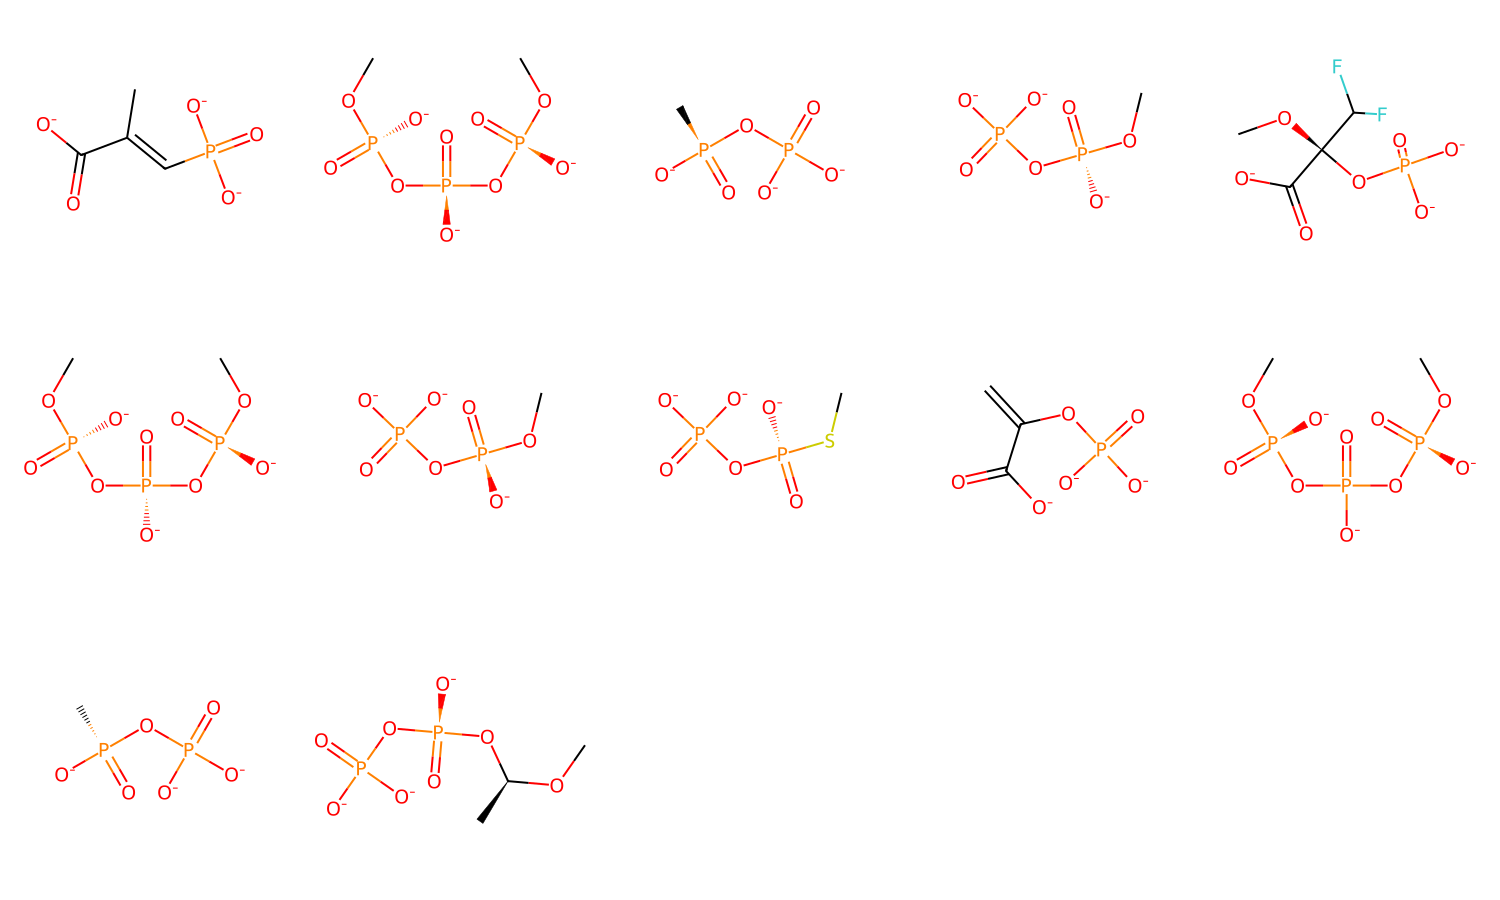

In [96]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

print(len(df_one.query("lig_group == 'Phosphate'")))
print(len(df_ntwo_lig.query("lig_group == 'Phosphate'")))
print(len(df_3_lig.query("lig_group == 'Phosphate'")))
print(len(df_4_lig.query("lig_group == 'Phosphate'")))


Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_3_lig['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

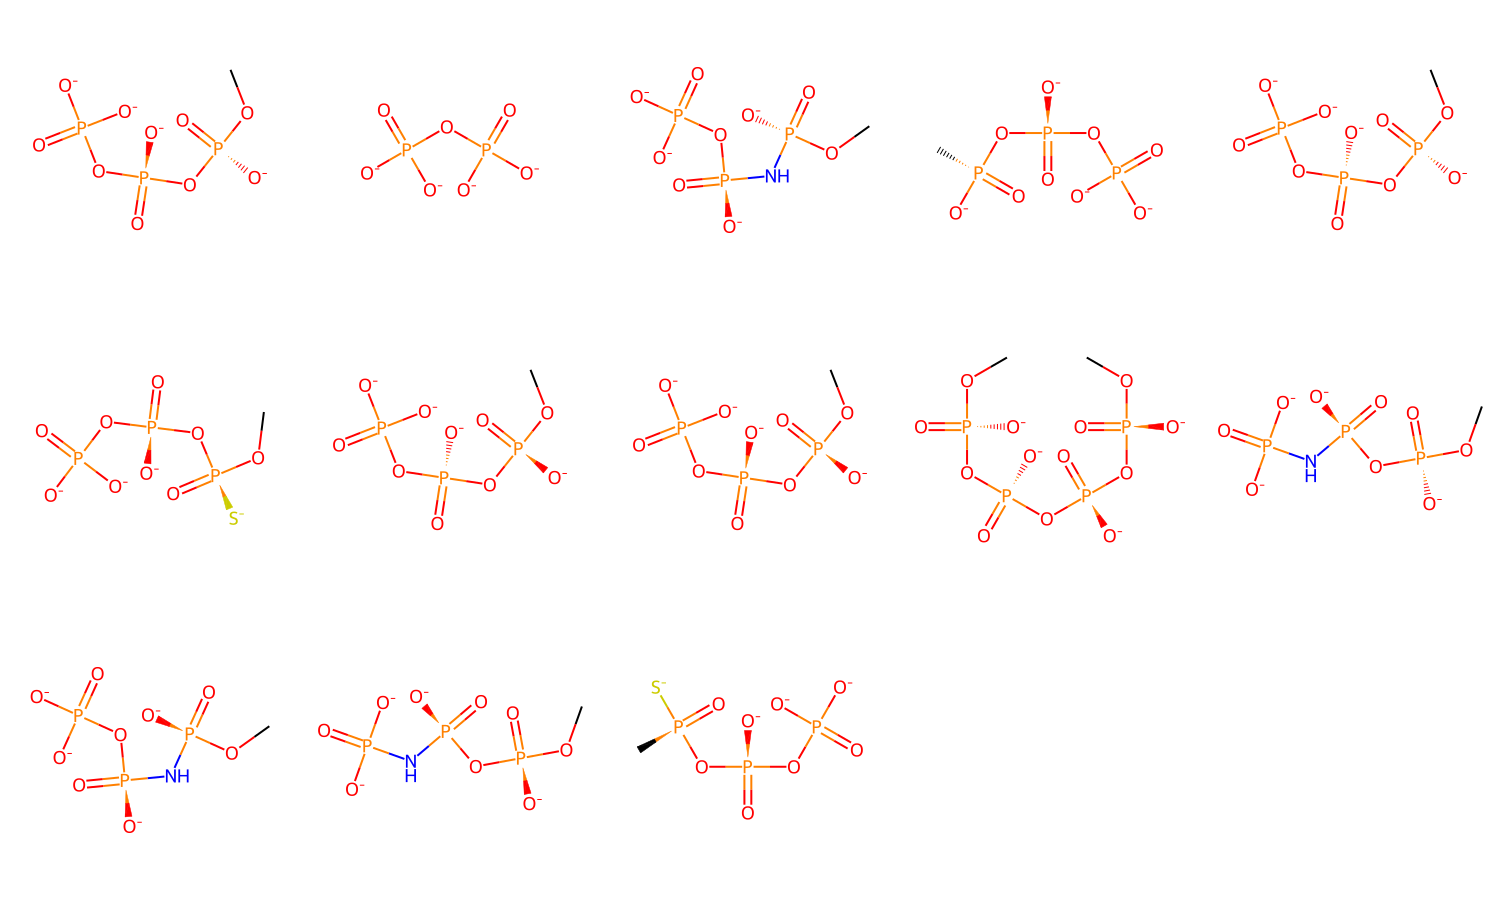

In [88]:
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_4_lig['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

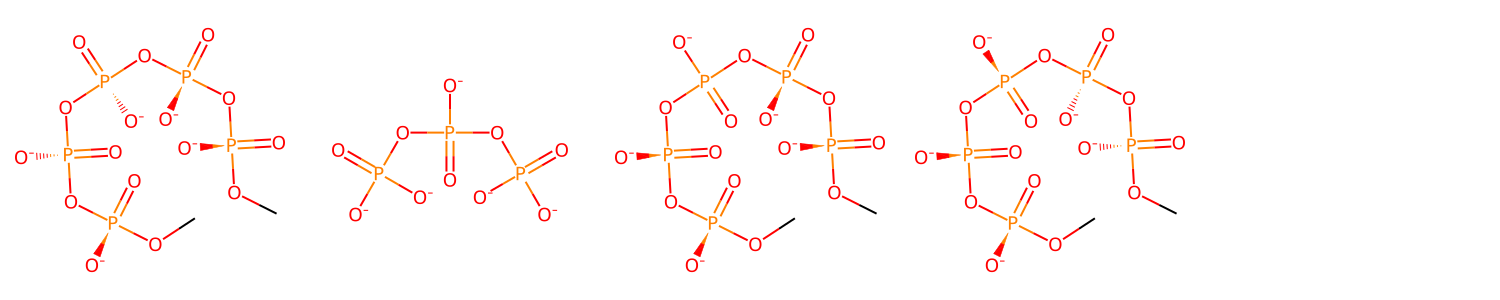

In [89]:
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_5_lig['smiles0'])], subImgSize=(300, 300), molsPerRow=5)


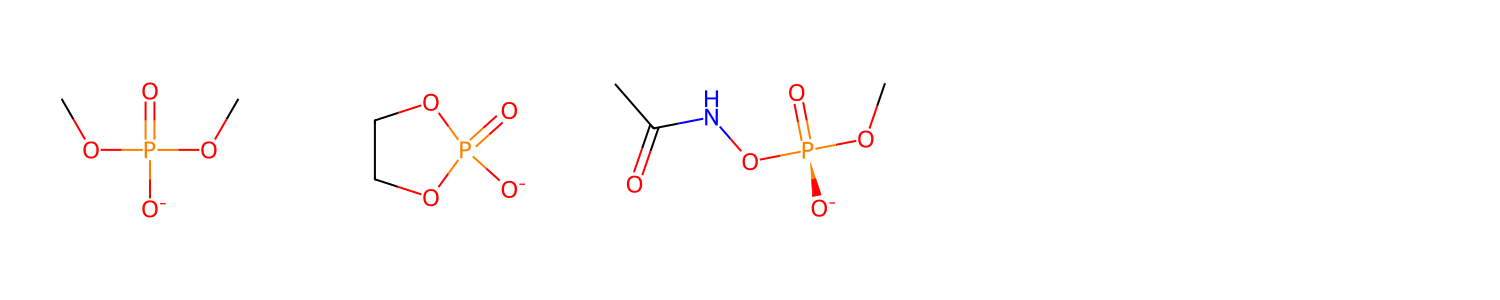

In [94]:
df_one_phosphate = df_one.query("lig_group == 'Phosphate'")
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_one_phosphate['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

In [119]:
# df_tertamine = df_one.query("lig_group == 'Tertamine'")
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_tertamine['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

# Single Charge Proteins and Ligands

In [ ]:
print('positive nitrogen protein: ')
print(len(df_one.query("restype == 'HIS'"))) # positive nitrogen
print(len(df_one.query("restype == 'ARG'")))
print(len(df_one.query("restype == 'LYS'")))

print('\nnegative oxygen protein: ')
print(len(df_one.query("restype == 'ASP'"))) # negative oxygen
print(len(df_one.query("restype == 'GLU'")))


print('\nnegative oxygen ligand: ')
print(len(df_one.query("lig_group == 'Sulfate'"))) # negative oxygen
print(len(df_one.query("lig_group == 'Sulfonicacid'")))
print(len(df_one.query("lig_group == 'Phosphate'")))
print(len(df_one.query("lig_group == 'Carboxylate'")))

print('\npositive nitrogen ligand: ')
print(len(df_one.query("lig_group == 'Tertamine'"))) # positive nitrogen
print(len(df_one.query("lig_group == 'Quartamine'")))

print('\npositive sulfur ligand: ')
print(len(df_one.query("lig_group == 'Sulfonium'"))) # positive sulfur

positive nitrogen protein: 
10
545
381

negative oxygen protein: 
299
158

negative oxygen ligand: 
16
54
45
821

positive nitrogen ligand: 
230
14

positive sulfur ligand: 
10


len: [1509, 467]
len: [936, 457]


Text(0.5, 1.0, 'Median Energies')

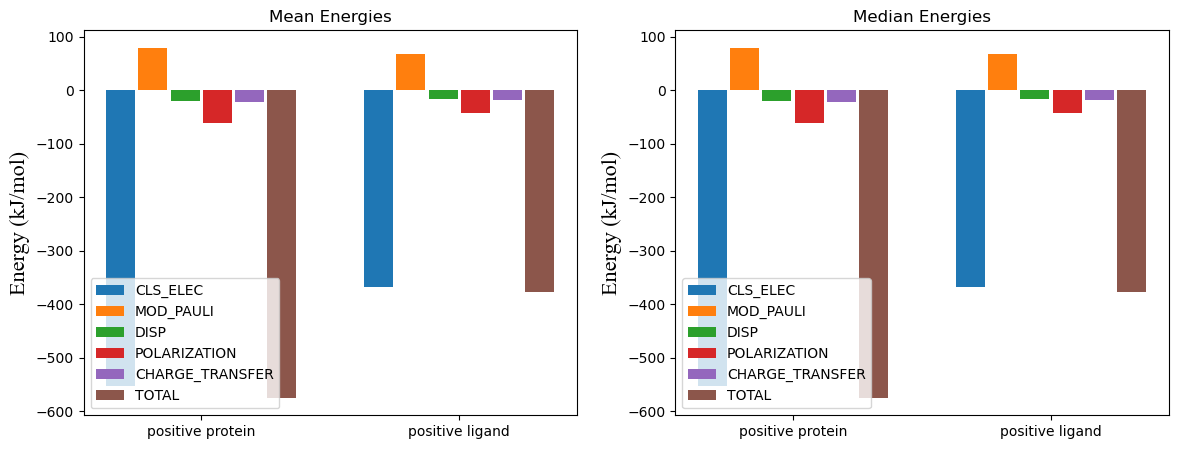

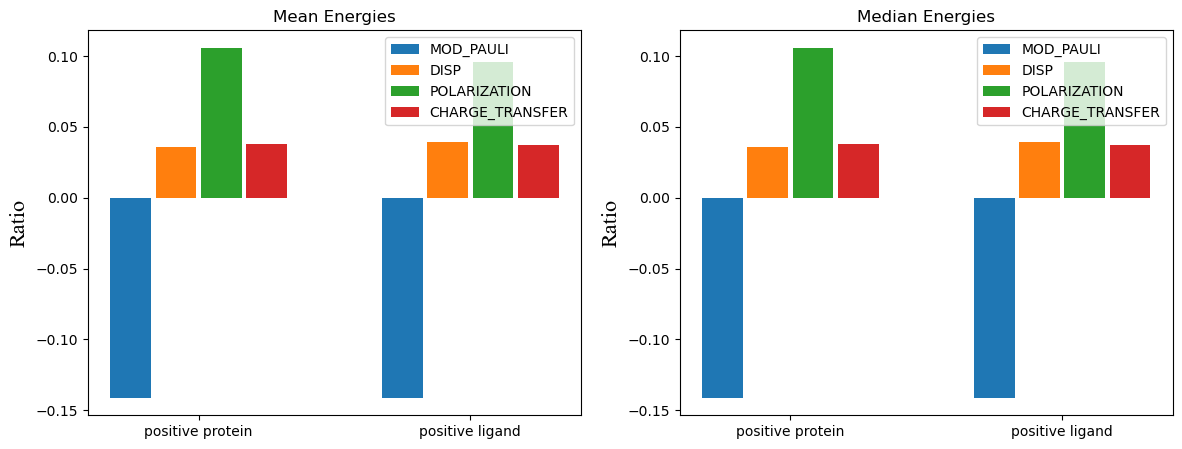

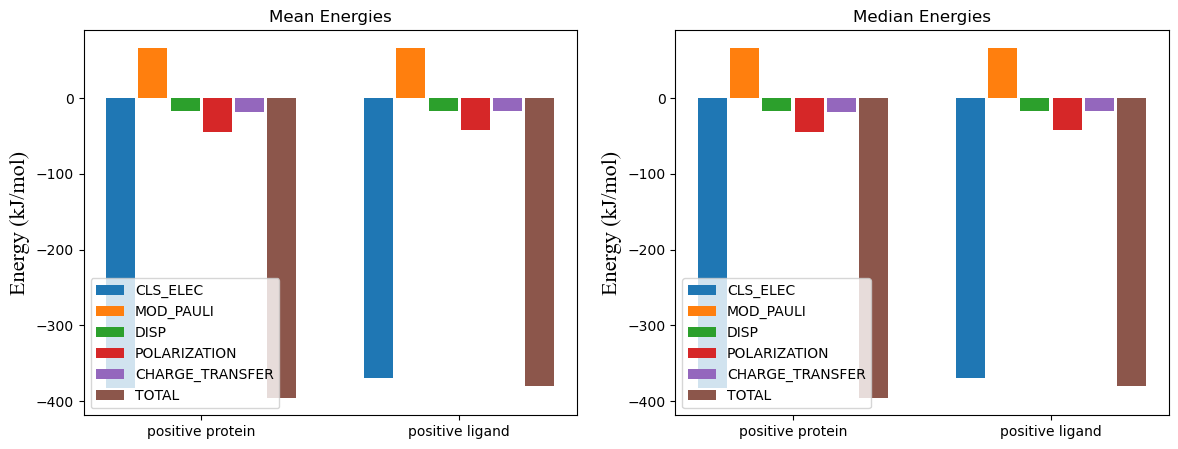

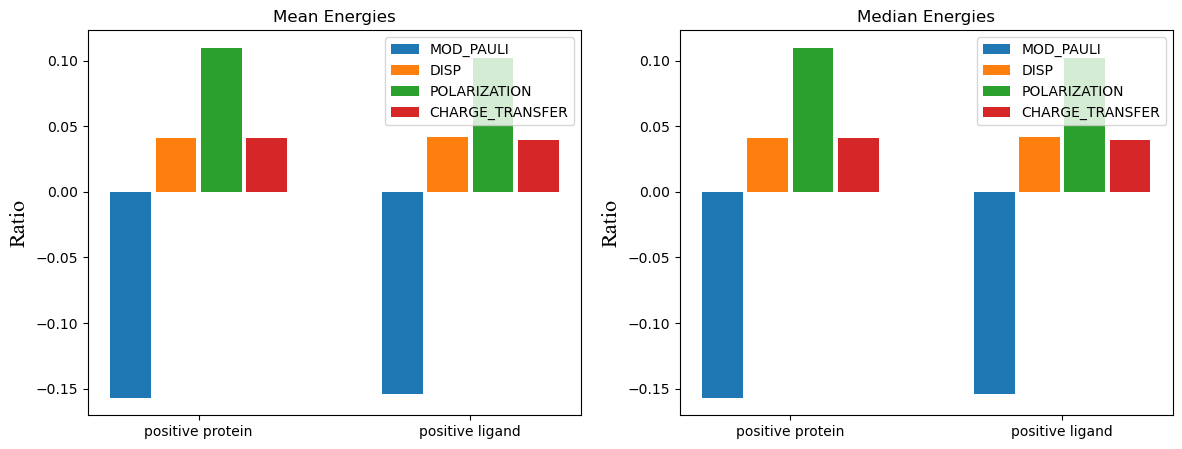

In [199]:
df_pos_prot = df.query("protispos == True")
df_pos_lig = df.query("protispos == False")

dfs = [df_pos_prot, df_pos_lig]
labels = ['positive protein', 'positive ligand']

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False)
axes[1].set_title('Median Energies')

items = [
    # 'FROZEN', 
    # 'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False, ratio2=True)
axes[1].set_title('Median Energies')


df_pos_prot = df_one.query("protispos == True")
df_pos_lig = df_one.query("protispos == False")

dfs = [df_pos_prot, df_pos_lig]
labels = ['positive protein', 'positive ligand']

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False)
axes[1].set_title('Median Energies')

items = [
    # 'FROZEN', 
    # 'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False, ratio2=True)
axes[1].set_title('Median Energies')

In [61]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

# Different Charge Phosphate Group

Text(0.5, 1.0, 'Mean Energies')

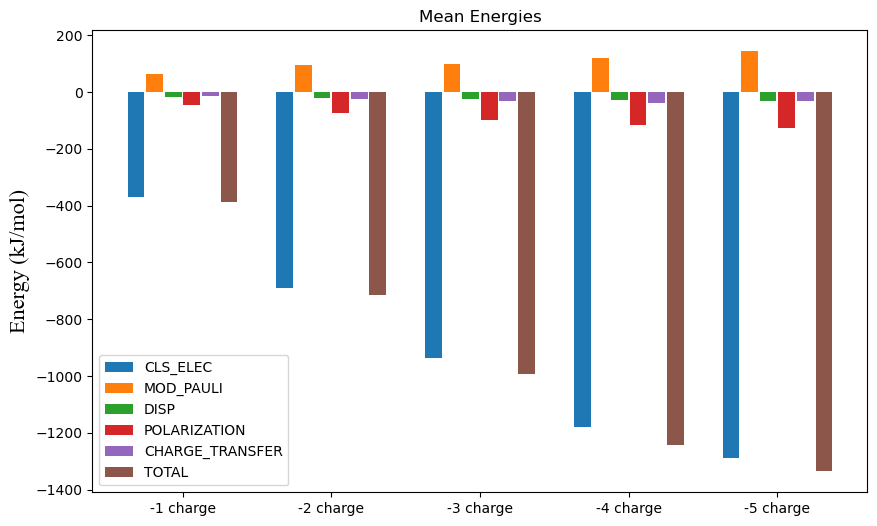

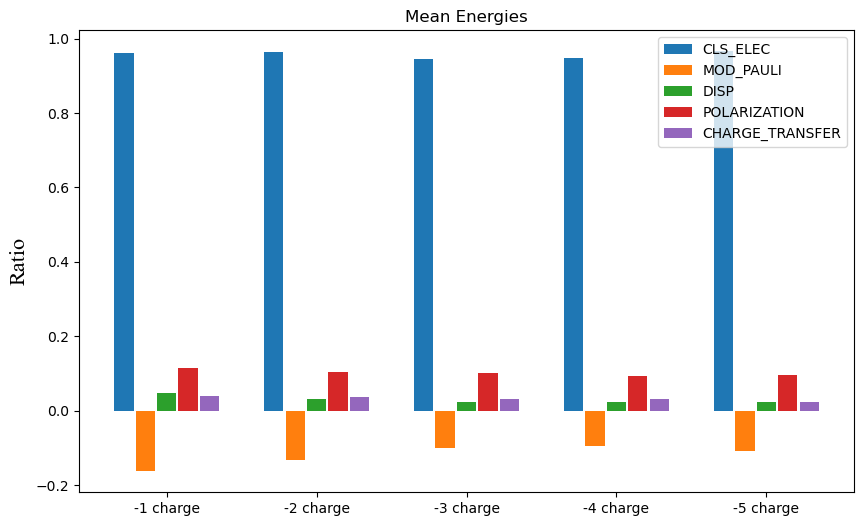

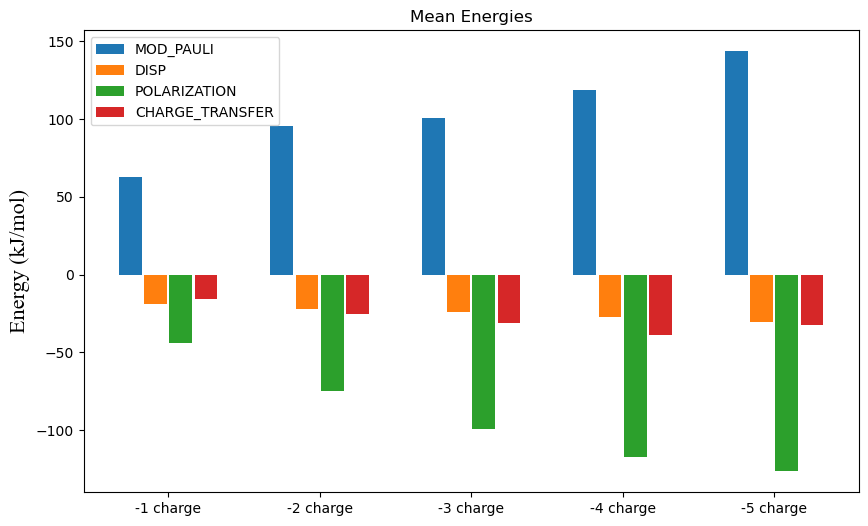

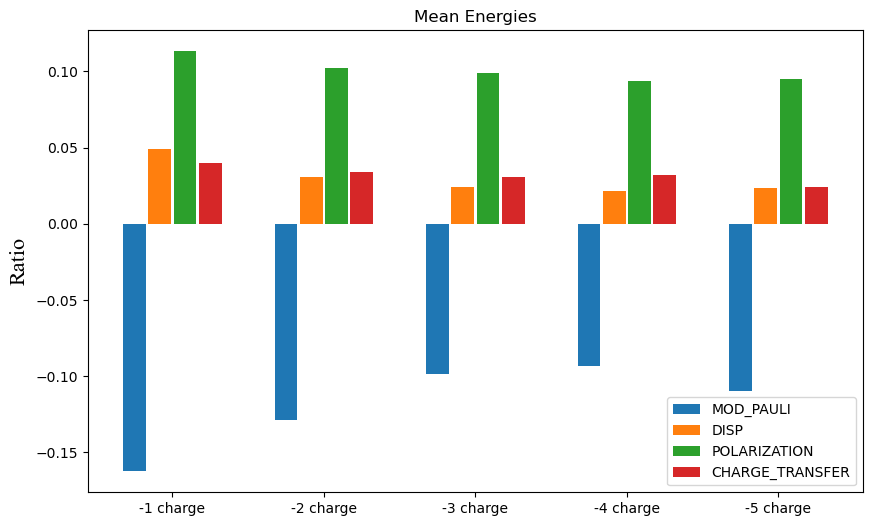

In [200]:
dfs = [df_one.query("lig_group == 'Phosphate'"), 
       df_ntwo_lig.query("lig_group == 'Phosphate'"), 
       df_3_lig.query("lig_group == 'Phosphate'"), 
       df_4_lig.query("lig_group == 'Phosphate'"), 
       df_5_lig.query("lig_group == 'Phosphate'")]
labels = ['-1 charge', '-2 charge', '-3 charge', '-4 charge', '-5 charge']


items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

fig, axes = plt.subplots(figsize=(10, 6))
plot('bar', (labels, items), dfs, axes)
axes.set_title('Mean Energies')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]



fig, axes = plt.subplots(figsize=(10, 6))
plot('bar', (labels, items), dfs, axes, ratio1=True)
axes.set_title('Mean Energies')


items = [
    # 'FROZEN', 
    # 'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]


fig, axes = plt.subplots(figsize=(10, 6))
plot('bar', (labels, items), dfs, axes)
axes.set_title('Mean Energies')


items = [
    # 'FROZEN', 
    # 'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]


fig, axes = plt.subplots(figsize=(10, 6))
plot('bar', (labels, items), dfs, axes, ratio2=True)
axes.set_title('Mean Energies')

# fig, axes = plt.subplots(figsize=(10, 6))
# plot('bar', (labels, items), dfs, axes, median=True, ratio1=True)
# axes.set_title('Median Energies')

# Differet Oxygen Compounds

In [190]:
df_carboxyl = df.query("restype == 'ASP' or restype == 'GLU' or lig_group == 'Carboxyl'")
df_phosphate = df.query("lig_group == 'Phosphate'")
df_sulfate = df.query("lig_group == 'Sulfate' or lig_group == 'Sulfonicacid'")

print(len(df_carboxyl))
print(len(df_phosphate))
print(len(df_sulfate))

df_list = [df_carboxyl, df_phosphate, df_sulfate]
labels = ['carboxyl', 'phosphate', 'sulfate']

467
589
71


# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_44497/1030292275.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


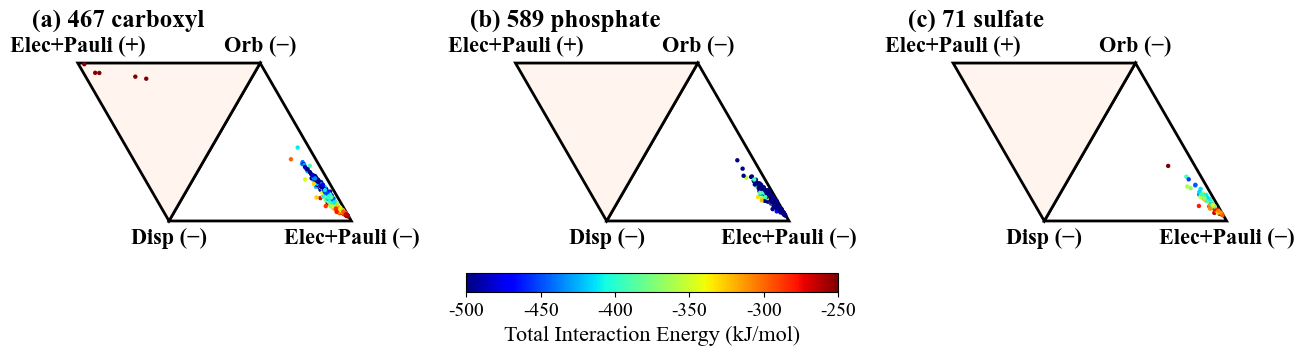

In [191]:
cmap_range = [-500, -250]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_list[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_list[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_list[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: [467, 589, 71]


Text(0.5, 1.0, 'Median Energies')

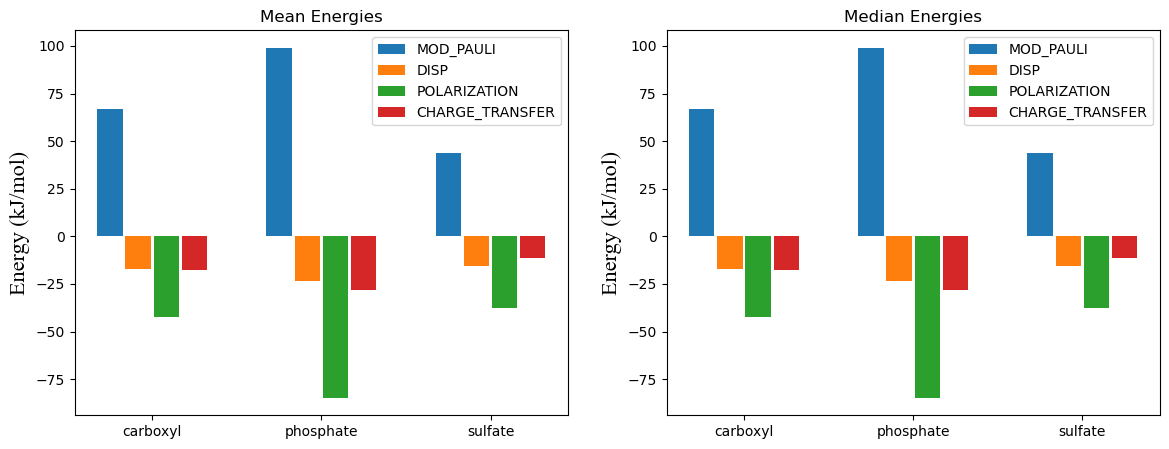

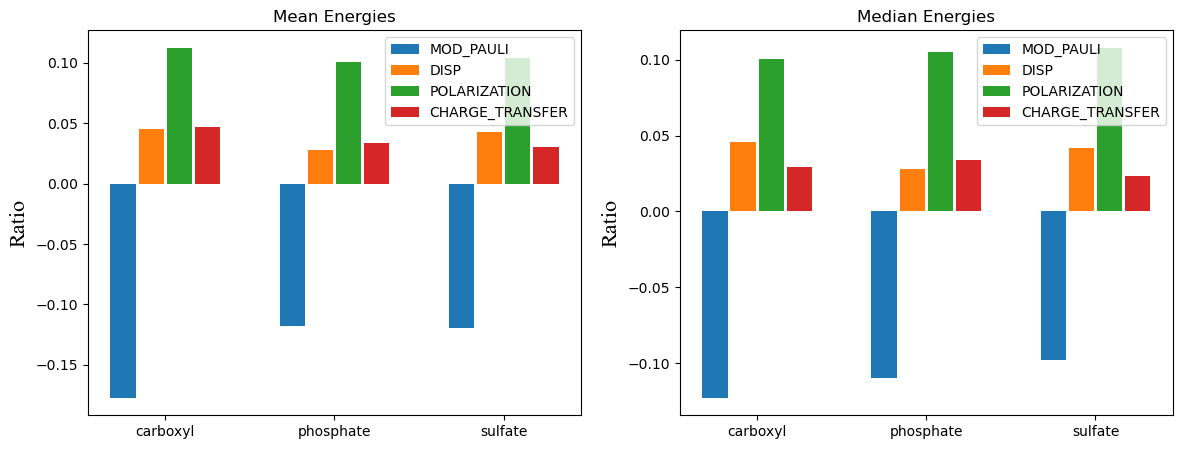

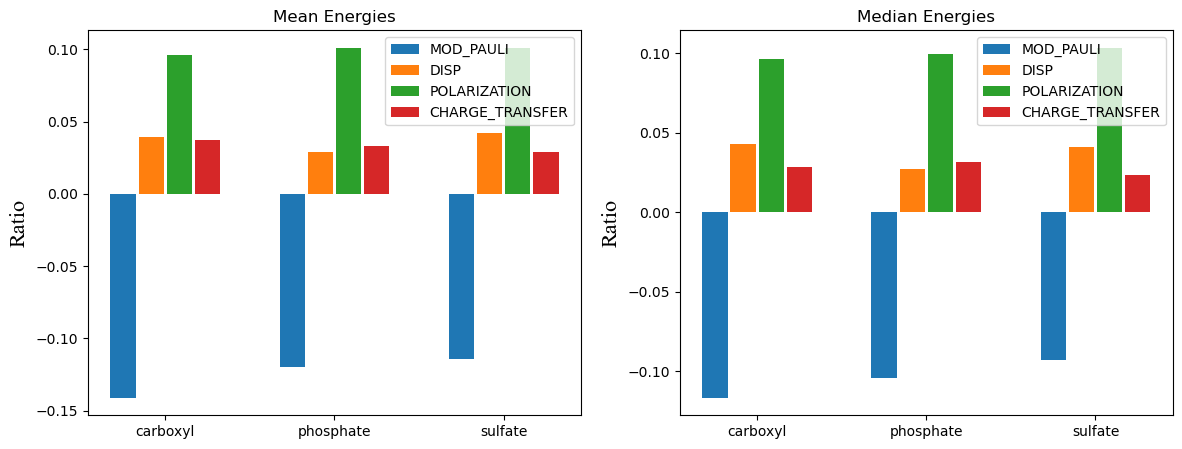

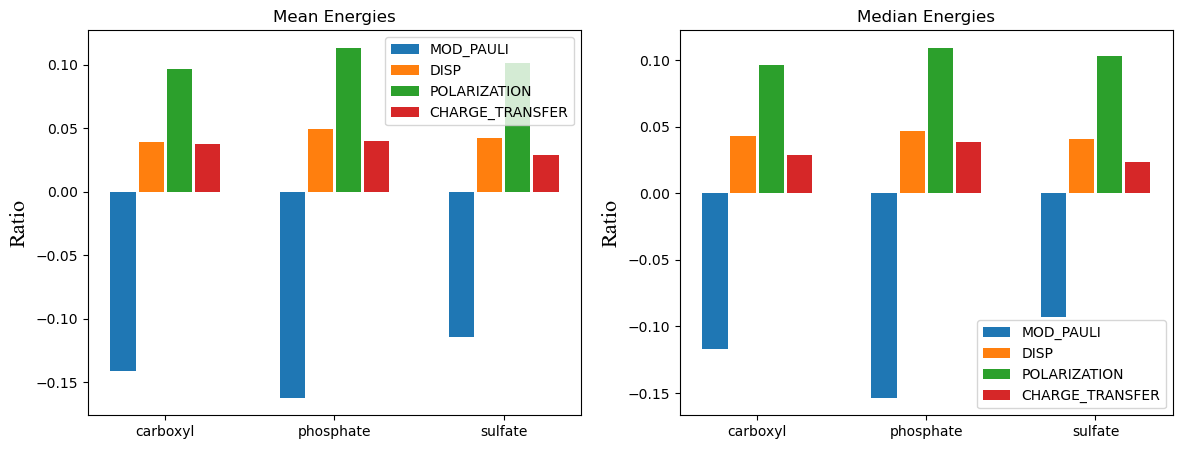

In [192]:
items = [
    # 'FROZEN', 
    # 'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

print(f'len: {list(map(len, df_list))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_list, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_list, axes[1], median=False)
axes[1].set_title('Median Energies')

items = [
    # 'FROZEN', 
    # 'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_list, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_list, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_list, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_list, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')



df_list = [df_carboxyl, df_one_phosphate, df_sulfate] # only single charged phosphates
labels = ['carboxyl', 'phosphate', 'sulfate']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_list, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_list, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')